# 02 – Ergebnisse

Liest die Dateien aus `results/` (erzeugt von `python run_all.py`). Es wird nichts neu trainiert.

In [20]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay
R = Path.cwd().parent / 'results'
res = {f.stem: json.loads(f.read_text()) for f in sorted(R.glob('*.json')) if 'history' not in f.stem}
pd.read_csv(R / 'summary.csv').round(4)

,method,split,n_test,roc_auc,acc,recall_def,precision_def,f1_def,false_alarms,hr_recall_def,hr_false_alarms,hr_missed,train_s
0,hog_logreg,clean,195,0.9934,0.9538,0.9658,0.9576,0.9617,0.0641,1.0000,0.2308,0,0.1
1,hog_svm_rbf,clean,195,0.9997,0.9897,0.9915,0.9915,0.9915,0.0128,0.9915,0.0256,1,1.1
2,small_cnn,clean,195,0.9966,0.9744,0.9573,1.0000,0.9782,0.0000,0.9573,0.0000,5,761.9
3,resnet18_frozen_logreg,clean,195,0.9950,0.9692,0.9829,0.9664,0.9746,0.0513,0.9829,0.0513,2,35.9
4,resnet18_finetune,clean,195,0.9999,0.9795,0.9658,1.0000,0.9826,0.0000,0.9658,0.0000,4,399.7
5,patchcore_anomaly,clean,195,0.9504,0.8000,0.6752,0.9875,0.8020,0.0128,0.9915,0.6538,1,183.4
6,ensemble_soft_vote,clean,195,0.9999,0.9949,0.9915,1.0000,0.9957,0.0000,0.9915,0.0000,1,NaN
7,ensemble_stacking,clean,195,0.9991,0.9949,0.9915,1.0000,0.9957,0.0000,0.9915,0.0000,1,NaN
8,hog_logreg,official,715,0.9927,0.9622,0.9757,0.9651,0.9704,0.0611,0.9845,0.1794,7,1.9
9,hog_svm_rbf,official,715,0.9999,0.9930,0.9912,0.9978,0.9945,0.0038,0.9912,0.0038,4,38.1


## Vergleich ROC-AUC und Accuracy

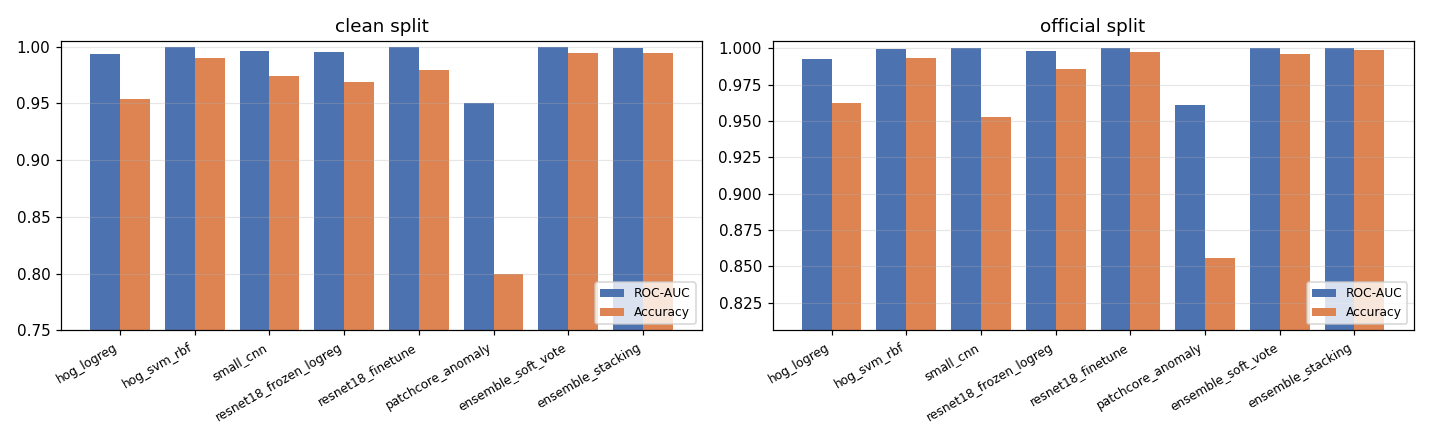

In [21]:
display(Image(filename=str(R / 'comparison.png')))

## ROC-Kurven
Die Kurven zeigen den Zielkonflikt zwischen gefundenen Defekten und Fehlalarmen für jede mögliche Schwelle.

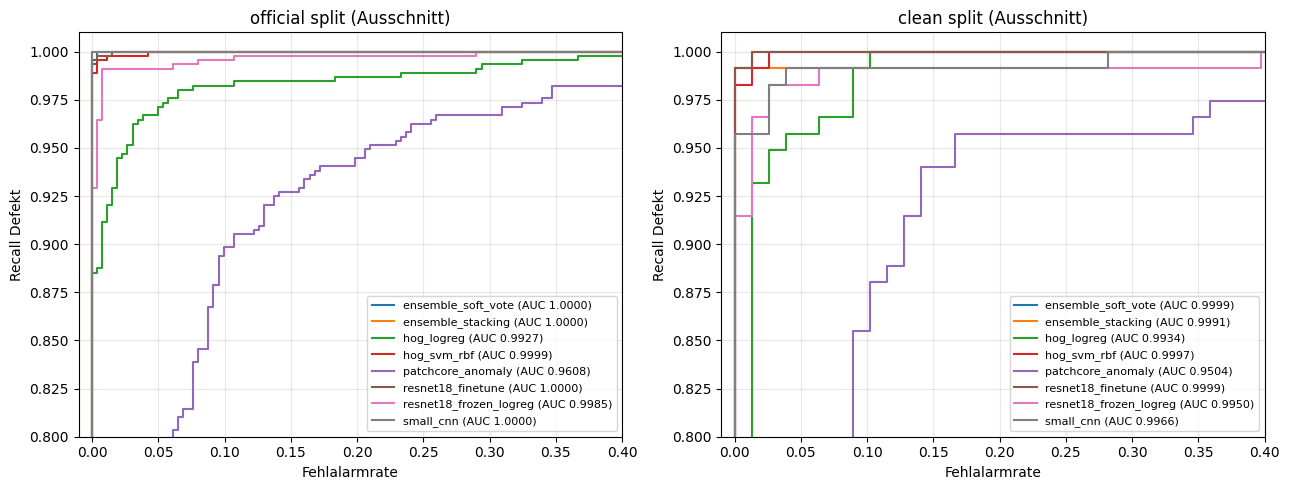

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, split in zip(axes, ['official', 'clean']):
    for name, r in res.items():
        if r['split'] != split: continue
        fpr, tpr, _ = roc_curve(r['scores']['y_test'], r['scores']['test'])
        ax.plot(fpr, tpr, label=f"{r['method']} (AUC {r['roc_auc']:.4f})")
    ax.set_xlim(-0.01, 0.4); ax.set_ylim(0.8, 1.01)
    ax.set_xlabel('Fehlalarmrate'); ax.set_ylabel('Recall Defekt'); ax.set_title(f'{split} split (Ausschnitt)')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Konfusionsmatrizen (Test, Default-Schwelle)

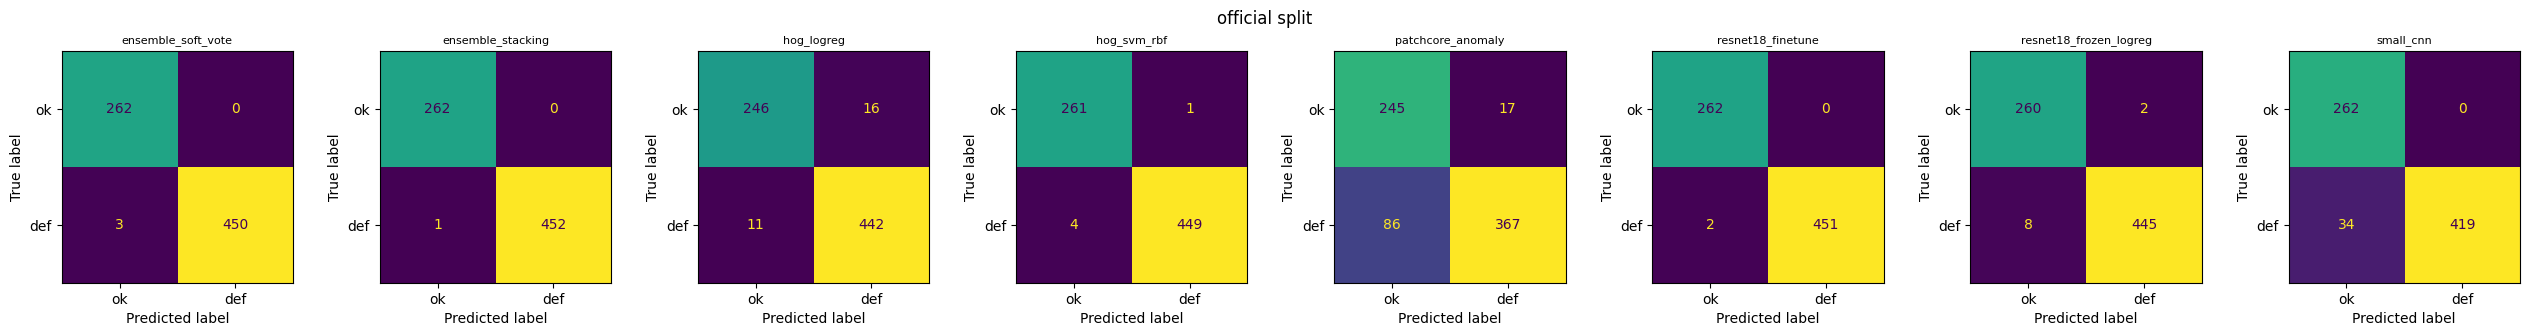

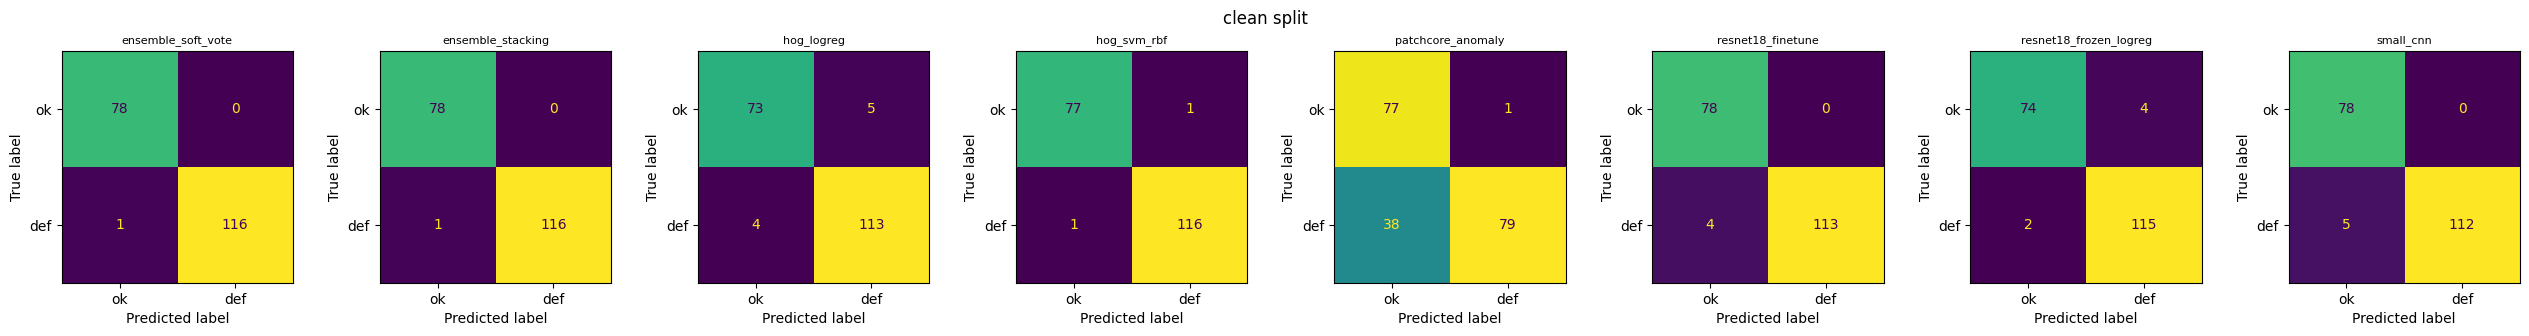

In [18]:
for split in ['official', 'clean']:
    items = [r for r in res.values() if r['split'] == split]
    fig, axes = plt.subplots(1, len(items), figsize=(3.2 * len(items), 3.2))
    for ax, r in zip(axes, items):
        y, s, thr = np.array(r['scores']['y_test']), np.array(r['scores']['test']), r['default']['threshold']
        ConfusionMatrixDisplay(confusion_matrix(y, (s >= thr).astype(int)), display_labels=['ok', 'def']).plot(ax=ax, colorbar=False)
        ax.set_title(r['method'], fontsize=8)
    fig.suptitle(f'{split} split'); plt.tight_layout(); plt.show()

## Score-Verteilung des kleinen CNN
AUC 1,0 auf `official`, aber bei Schwelle 0,5 werden Defekte übersehen. Die Klassen sind getrennt, nur liegt die Grenze nicht bei 0,5.

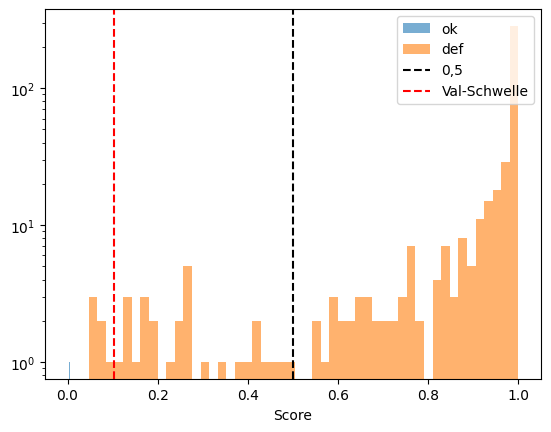

In [17]:
r = res['small_cnn_official']
y, s = np.array(r['scores']['y_test']), np.array(r['scores']['test'])
plt.hist(s[y == 0], bins=50, alpha=0.6, label='ok'); plt.hist(s[y == 1], bins=50, alpha=0.6, label='def')
plt.axvline(0.5, color='k', ls='--', label='0,5'); plt.axvline(r['recall99']['threshold'], color='r', ls='--', label='Val-Schwelle')
plt.yscale('log'); plt.xlabel('Score'); plt.legend(); plt.show()

## Erklärbarkeit: Grad-CAM und Anomalie-Heatmaps

**gradcam_resnet18_official.png**

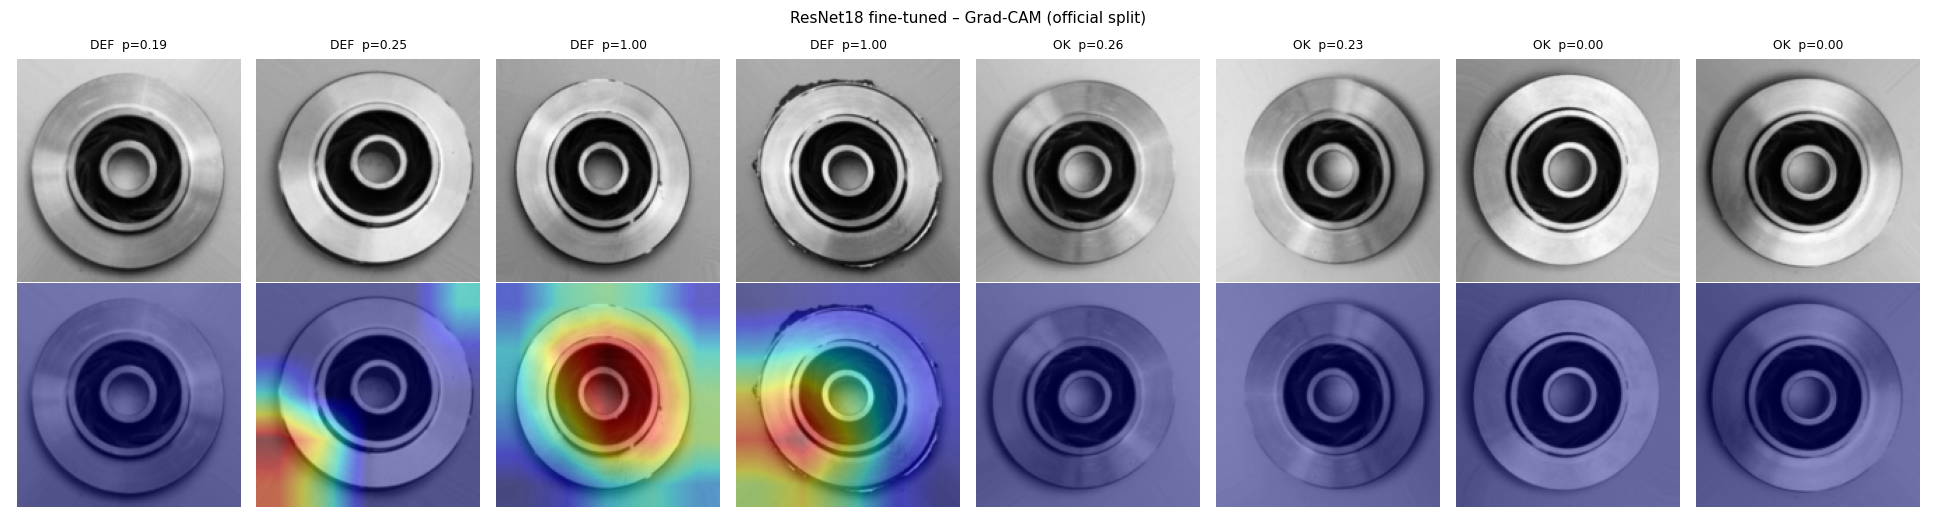

**gradcam_small_cnn_official.png**

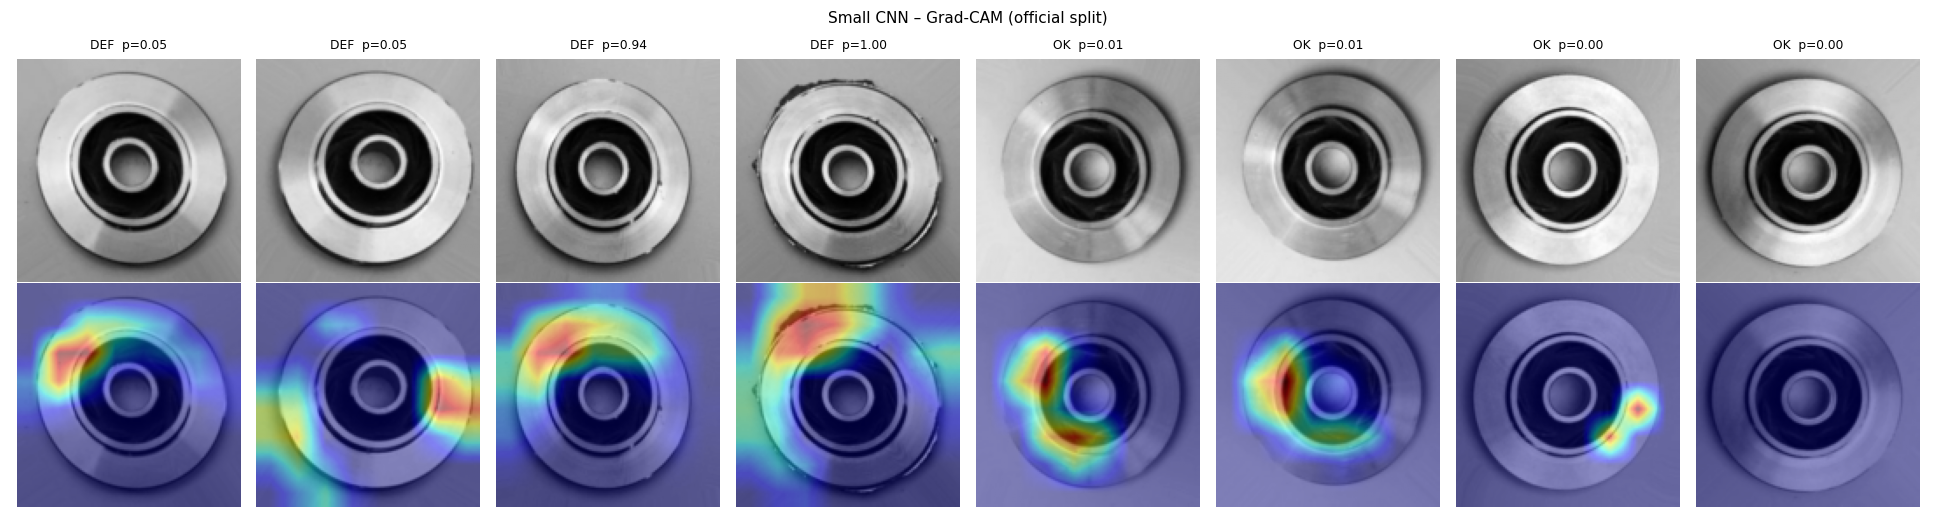

**anomaly_maps_official.png**

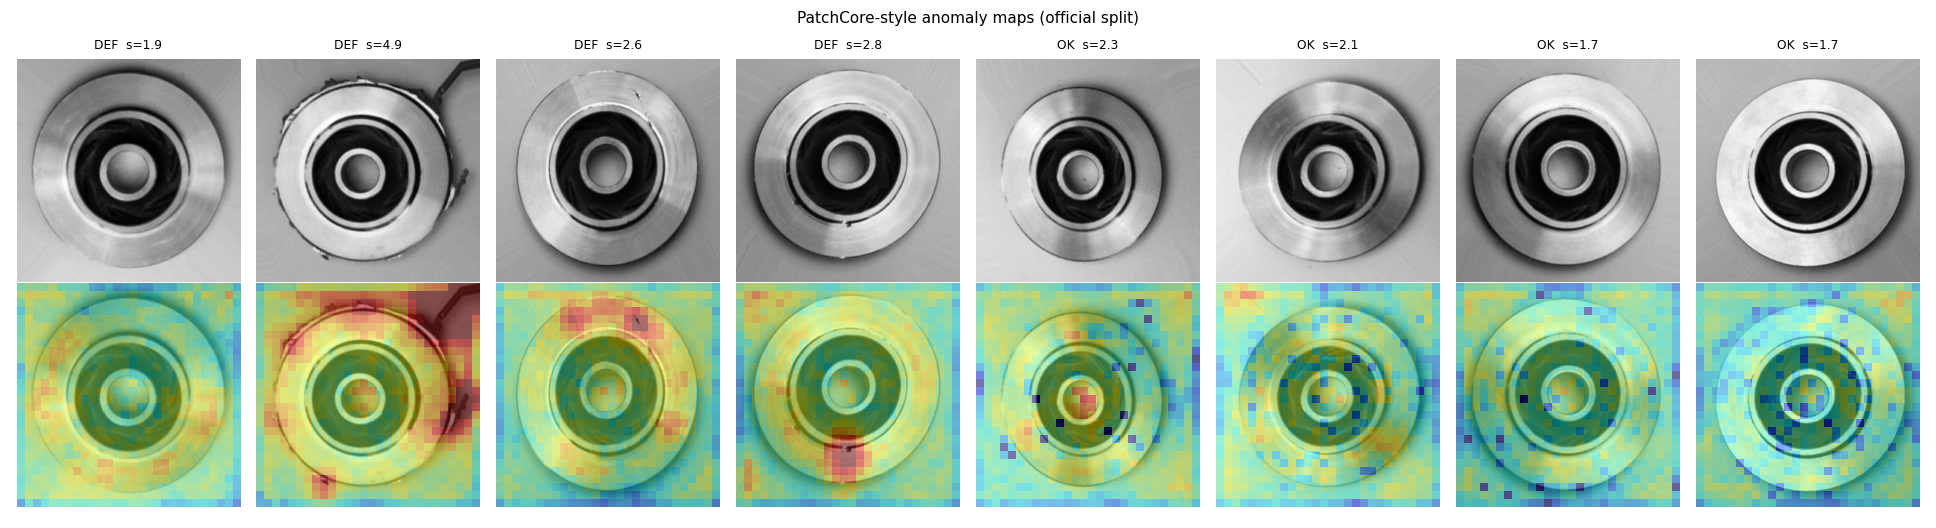

**gradcam_resnet18_clean.png**

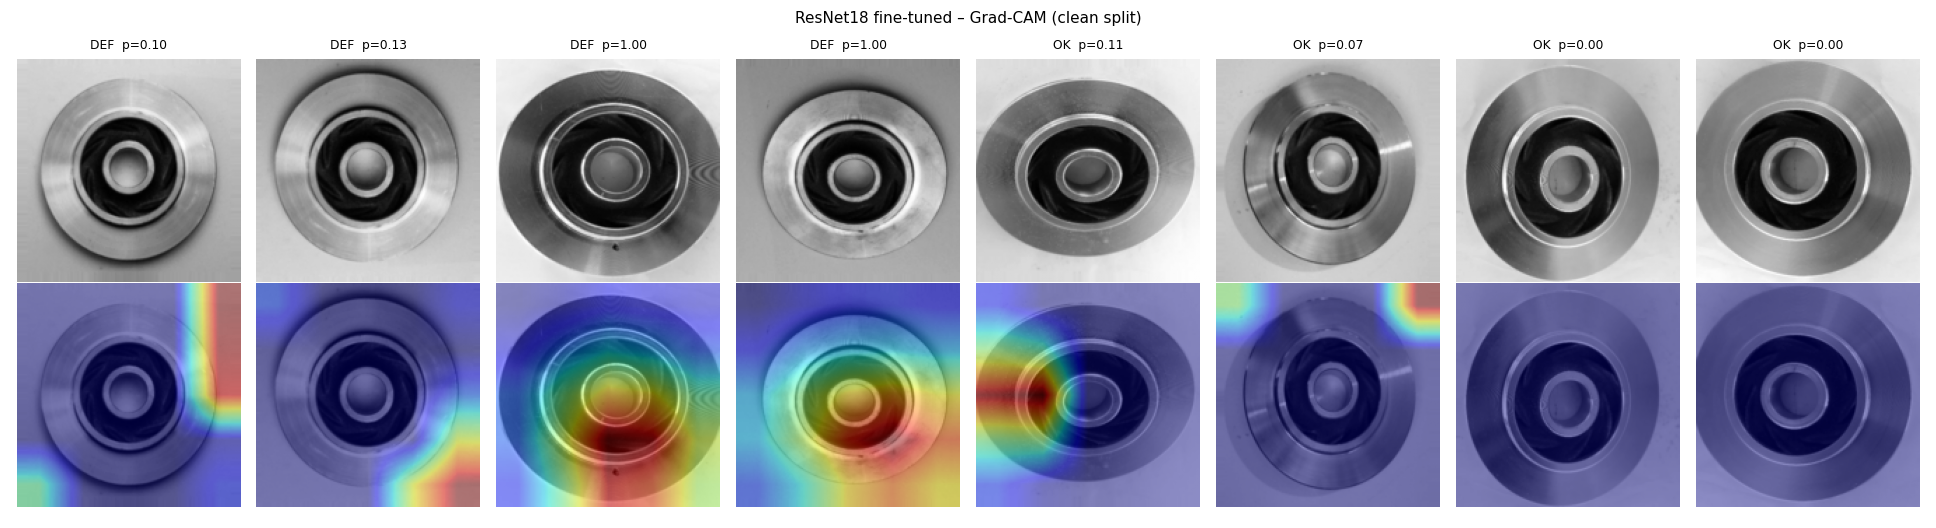

**anomaly_maps_clean.png**

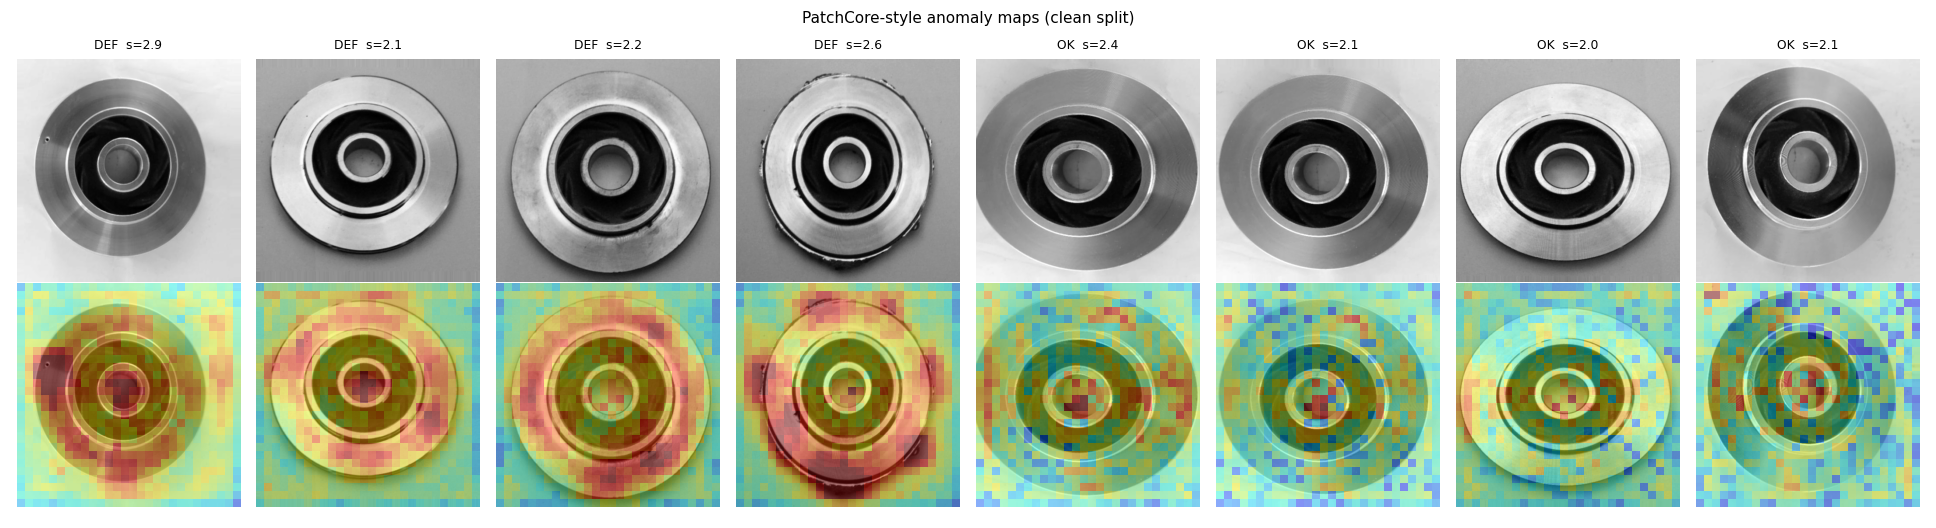

In [16]:
for f in ['gradcam_resnet18_official.png', 'gradcam_small_cnn_official.png', 'anomaly_maps_official.png',
          'gradcam_resnet18_clean.png', 'anomaly_maps_clean.png']:
    display(Markdown(f'**{f}**')); display(Image(filename=str(R / f)))